First we had to process a log where 3 people's recordings got appended. We had to split the recording in the 3 corresponding logs per person.

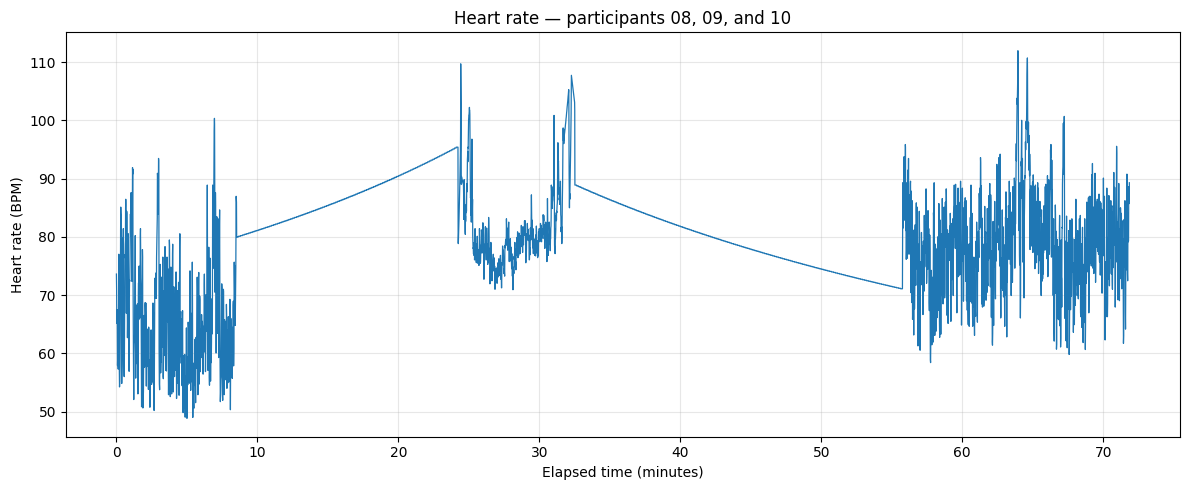

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

csv_path = Path(
    "/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr/"
    "test39_39_20261102_163128_IBI_participant_08_09_10.csv"
)

df = pd.read_csv(csv_path, sep=";", skiprows=2)
rr_ms = pd.to_numeric(df["Artifact corrected RR"], errors="coerce").dropna()
rr_ms = rr_ms[rr_ms > 0]

heart_rate = 60_000 / rr_ms
elapsed_minutes = rr_ms.cumsum() / 60_000

plt.figure(figsize=(12, 5))
plt.plot(elapsed_minutes, heart_rate, linewidth=0.9)
plt.title("Heart rate — participants 08, 09, and 10")
plt.xlabel("Elapsed time (minutes)")
plt.ylabel("Heart rate (BPM)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

#plt.savefig(csv_path.with_name("heart_rate_participants_08_09_10.png"), dpi=200)
plt.show()

We treated a long stretch as a pause in between recordings when the corrected RR changes by no more than 1 ms per beat for at least 30 seconds. It prints estimated boundary times, removes those gap rows, and saves three separate CSVs.

In [15]:
import csv
from datetime import datetime, timedelta

combined_file = Path(
    "/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr/"
    "test39_39_20261102_163128_IBI_participant_08_09_10.csv"
)
with combined_file.open(encoding='utf-8-sig', newline='') as f:
    source_rows = list(csv.reader(f, delimiter=';'))
data_rows = source_rows[3:]
metadata_rows = source_rows[:3]
metadata_text = combined_file.read_text(encoding='utf-8-sig').splitlines()
recording_start = datetime.strptime(metadata_text[1].replace('Start time:', '').strip(), '%d.%m.%Y %H:%M:%S')

# Detect long flat stretches in the change plot.
flat_flags = []
previous_corrected = None
for row in data_rows:
    corrected = float(row[1]) if row[1].strip() else None
    artifact = float(row[2]) if row[2].strip() else 0
    flat_flags.append(
        corrected is not None and previous_corrected is not None
        and artifact == 2 and abs(corrected - previous_corrected) <= 1
    )
    if corrected is not None:
        previous_corrected = corrected

gap_runs = []
i = 0
while i < len(data_rows):
    if not flat_flags[i]:
        i += 1
        continue
    j = i
    while j + 1 < len(data_rows) and flat_flags[j + 1]:
        j += 1
    duration = sum(float(r[1]) for r in data_rows[i:j + 1] if r[1].strip()) / 1000
    if duration >= 30:
        gap_runs.append((i, j, duration))
    i = j + 1

if len(gap_runs) != 2:
    raise ValueError(f'Expected two long gaps, found {len(gap_runs)}. Adjust the thresholds after reviewing the plot.')

def elapsed_before(row_index):
    return sum(float(r[1]) for r in data_rows[:row_index] if r[1].strip()) / 1000

print('Estimated gap intervals:')
for number, (first, last, duration) in enumerate(gap_runs, start=1):
    gap_start = recording_start + timedelta(seconds=elapsed_before(first))
    gap_end = recording_start + timedelta(seconds=elapsed_before(last + 1))
    print(f'Gap {number}: rows {first + 1}–{last + 1}, {gap_start:%Y-%m-%d %H:%M:%S} to {gap_end:%Y-%m-%d %H:%M:%S} ({duration / 60:.1f} min)')

segments = [
    (0, gap_runs[0][0] - 1),
    (gap_runs[0][1] + 1, gap_runs[1][0] - 1),
    (gap_runs[1][1] + 1, len(data_rows) - 1),
]
output_dir = Path("/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr")
output_dir.mkdir(exist_ok=True)
for person, (first, last) in enumerate(segments, start=1):
    segment_start = recording_start + timedelta(seconds=elapsed_before(first))
    output_file = output_dir / f'{combined_file.stem}_recording_{person}.csv'
    with output_file.open('w', encoding='utf-8', newline='') as f:
        writer = csv.writer(f, delimiter=';', lineterminator='\n')
        writer.writerow(metadata_rows[0])
        writer.writerow([f'Start time: {segment_start:%d.%m.%Y %H:%M:%S}'])
        writer.writerow(metadata_rows[2])
        writer.writerows(data_rows[first:last + 1])
    print(f'Recording {person}: data rows {first + 1}–{last + 1}, {last - first + 1} rows -> {output_file}')

Estimated gap intervals:
Gap 1: rows 558–1922, 2026-11-02 16:40:00 to 2026-11-02 16:55:41 (15.7 min)
Gap 2: rows 2609–4443, 2026-11-02 17:03:59 to 2026-11-02 17:27:13 (23.2 min)
Recording 1: data rows 1–557, 557 rows -> /Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr/test39_39_20261102_163128_IBI_participant_08_09_10_recording_1.csv
Recording 2: data rows 1923–2608, 686 rows -> /Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr/test39_39_20261102_163128_IBI_participant_08_09_10_recording_2.csv
Recording 3: data rows 4444–5709, 1266 rows -> /Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr/test39_39_20261102_163128_IBI_participant_08_09_10_recording_3.csv


We renamed manually the files to match the naming with the other files, then visualised the recordings to make sure the cut was performed correctly.

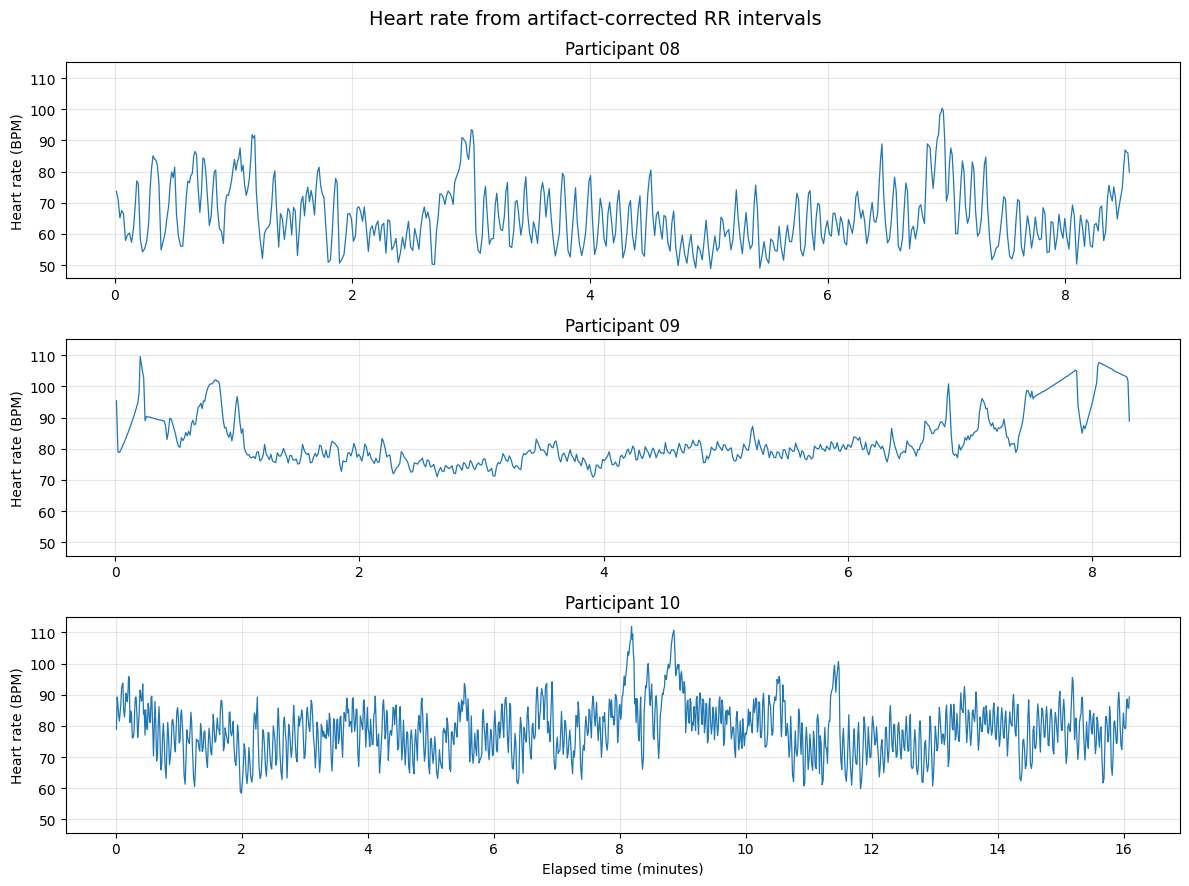

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

data_dir = Path(
    "/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data/raw_hr"
)

files = {
    "Participant 08": data_dir / "test39_39_20261102_163128_IBI_participant_08.csv",
    "Participant 09": data_dir / "test39_39_20261102_163128_IBI_participant_09.csv",
    "Participant 10": data_dir / "test39_39_20261102_163128_IBI_participant_10.csv",
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharey=True)

for ax, (participant, path) in zip(axes, files.items()):
    df = pd.read_csv(path, sep=";", skiprows=2)
    rr_ms = pd.to_numeric(df["Artifact corrected RR"], errors="coerce").dropna()
    rr_ms = rr_ms[rr_ms > 0]

    heart_rate = 60_000 / rr_ms
    elapsed_minutes = rr_ms.cumsum() / 60_000

    ax.plot(elapsed_minutes, heart_rate, linewidth=0.9)
    ax.set_title(participant)
    ax.set_ylabel("Heart rate (BPM)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Elapsed time (minutes)")
fig.suptitle("Heart rate from artifact-corrected RR intervals", fontsize=14)
fig.tight_layout()

#plt.savefig(data_dir / "heart_rate_participants_08_09_10.png", dpi=200)
plt.show()

We plotted all the participants.

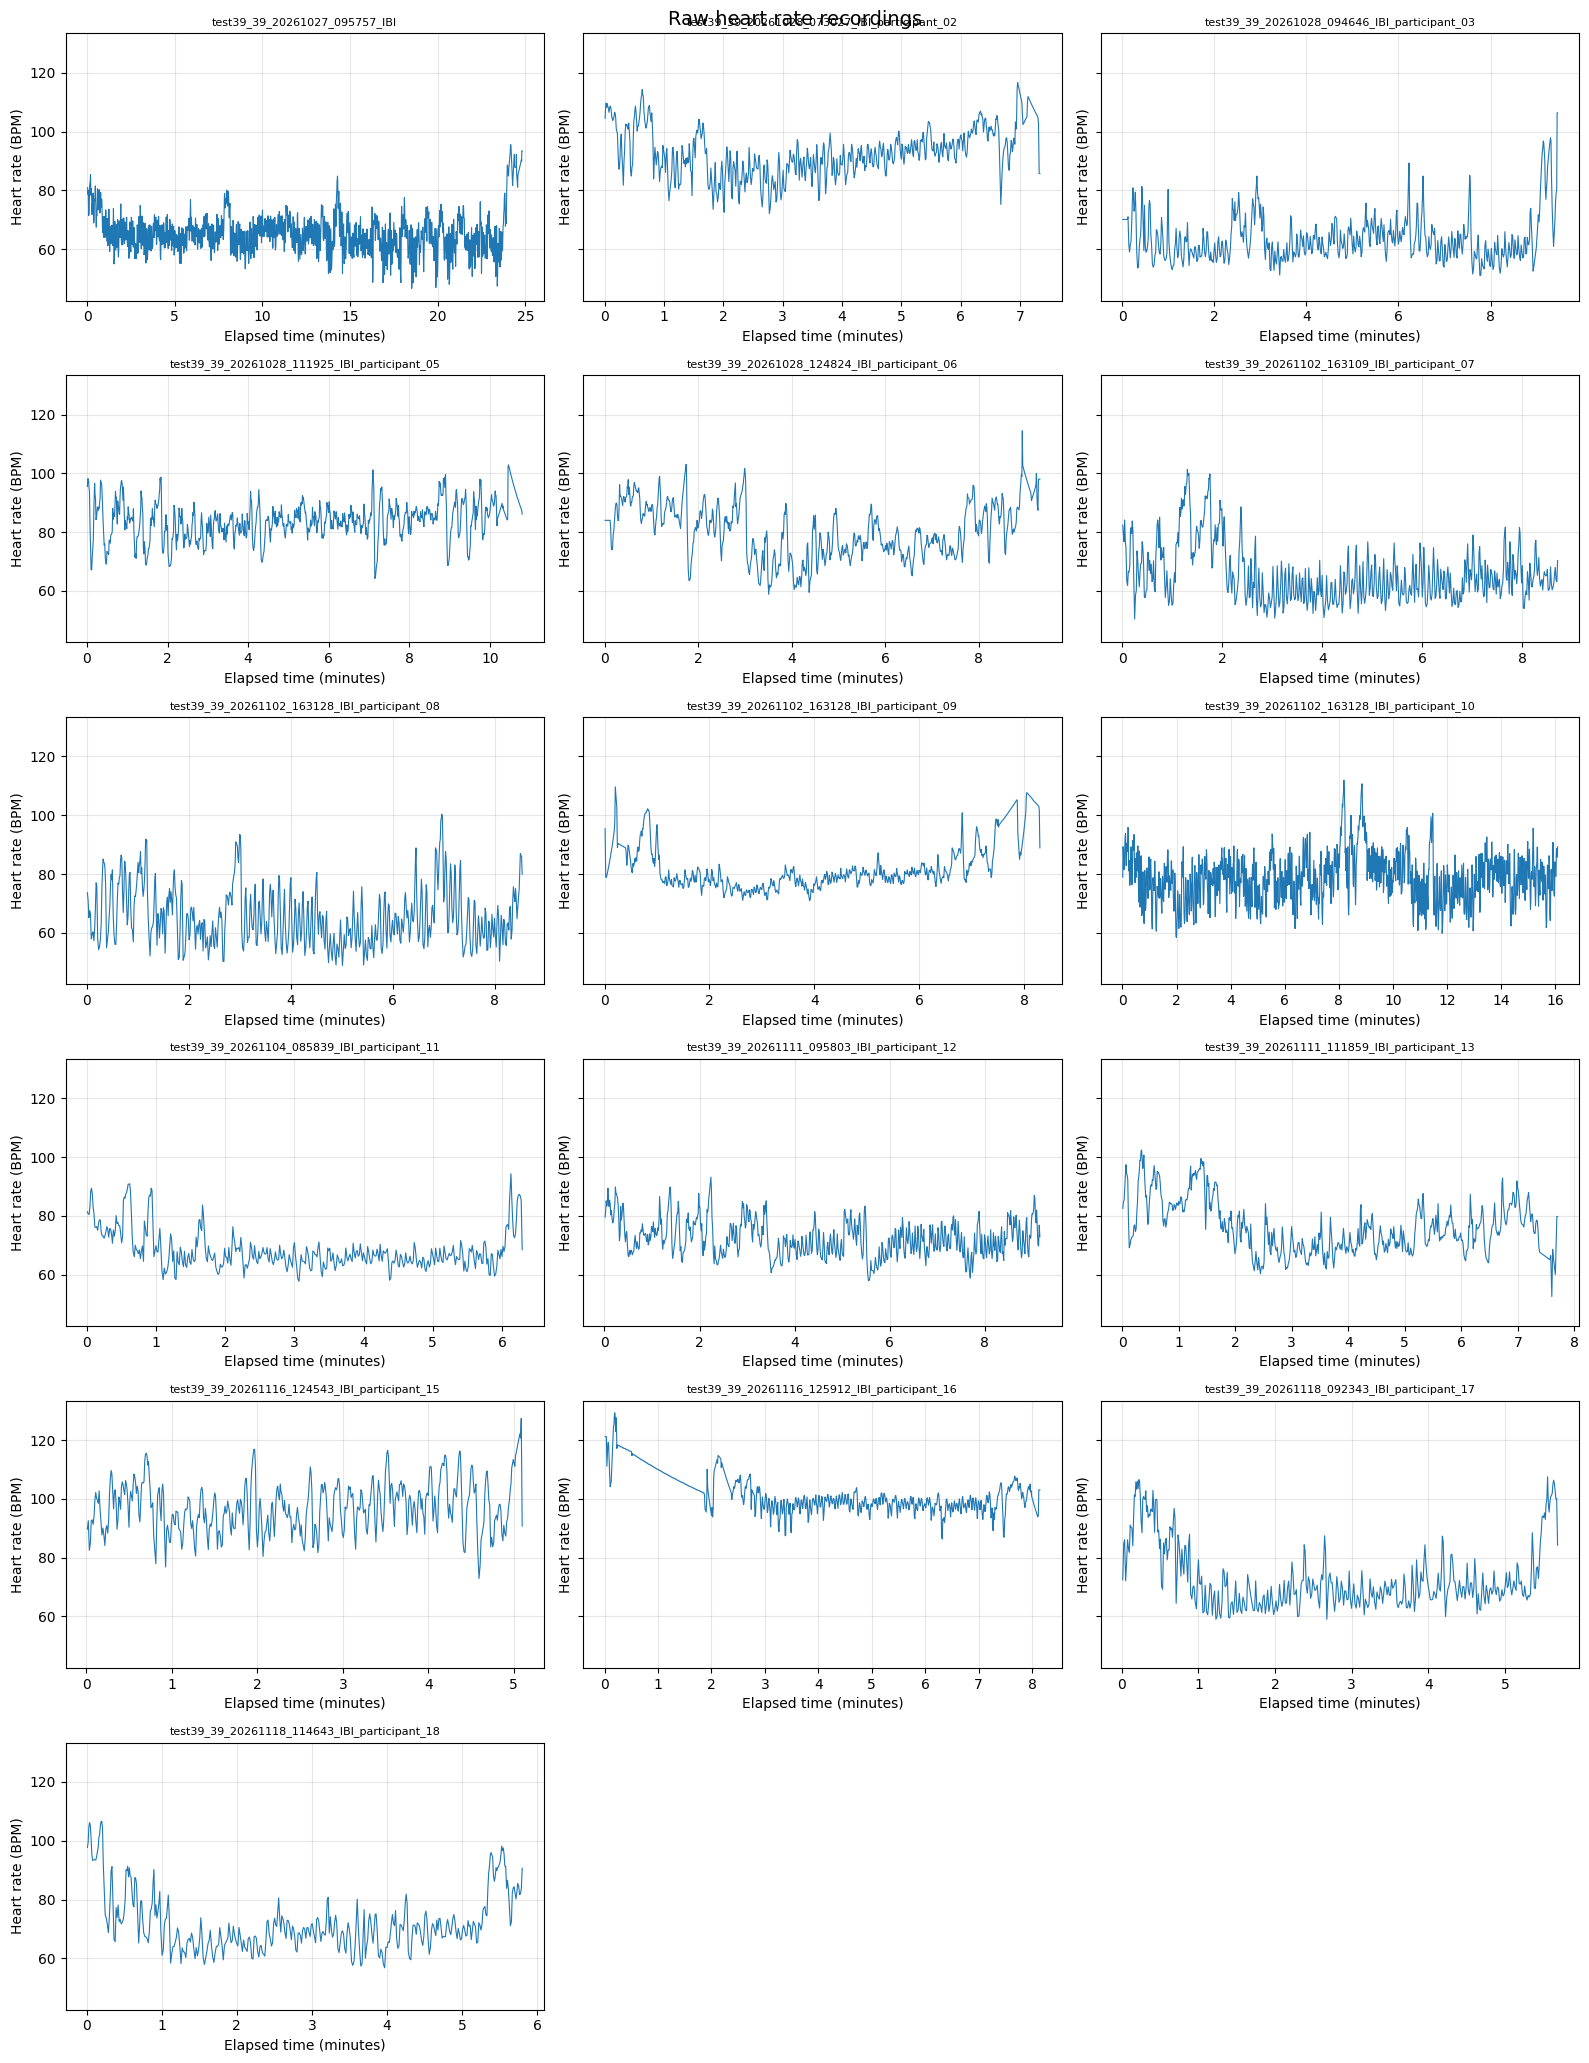

In [ ]:
import csv
import math
from pathlib import Path

import matplotlib.pyplot as plt

DATA_DIR = Path("data")
PARTICIPANT_DIR = Path("data copy")
if not PARTICIPANT_DIR.exists():
    PARTICIPANT_DIR = DATA_DIR

RAW_HR_DIR = PARTICIPANT_DIR / "raw_hr"
if not RAW_HR_DIR.exists():
    RAW_HR_DIR = DATA_DIR / "raw_hr"

EXCLUDED_FILE = RAW_HR_DIR / (
    "test39_39_20261102_163128_IBI_participant_08_09_10.csv"
)

PLOT_DIR = Path("data-cut") / "raw_hr_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

hr_files = [
    path
    for path in sorted(RAW_HR_DIR.glob("*.csv"))
    if path.resolve() != EXCLUDED_FILE.resolve()
]

columns = 3
rows = math.ceil(len(hr_files) / columns)
fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(16, 3.5 * rows),
    sharey=True,
    squeeze=False,
)

for ax, hr_file in zip(axes.flat, hr_files):
    with hr_file.open(encoding="utf-8-sig", newline="") as f:
        source_rows = list(csv.reader(f, delimiter=";"))

    data_rows = source_rows[3:]
    elapsed_minutes = []
    heart_rate_bpm = []
    elapsed_seconds = 0.0

    for row in data_rows:
        if len(row) < 2 or not row[1].strip():
            continue

        rr_ms = float(row[1])
        if rr_ms <= 0:
            continue

        elapsed_seconds += rr_ms / 1000
        elapsed_minutes.append(elapsed_seconds / 60)
        heart_rate_bpm.append(60_000 / rr_ms)

    ax.plot(elapsed_minutes, heart_rate_bpm, linewidth=0.8)
    ax.set_title(hr_file.stem, fontsize=8)
    ax.set_xlabel("Elapsed time (minutes)")
    ax.set_ylabel("Heart rate (BPM)")
    ax.grid(True, alpha=0.3)

for ax in axes.flat[len(hr_files):]:
    ax.set_visible(False)

fig.suptitle("Raw heart rate recordings", fontsize=14)
fig.tight_layout()
#fig.savefig(PLOT_DIR / "all_raw_hr_plots.png", dpi=200)
plt.show()

We then made a mapping between the HR data and the times recorded by our script in order to split each recording in the BPMs sections.

In [22]:
from pathlib import Path
from datetime import datetime
import csv
import re

import pandas as pd
from IPython.display import display

PROJECT_DIR = Path(
    "/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science"
)
DATA_DIR = PROJECT_DIR / "data"
PARTICIPANT_DIR = DATA_DIR
RAW_HR_DIR = DATA_DIR / "raw_hr"

EXCLUDED_FILE = RAW_HR_DIR / (
    "test39_39_20261102_163128_IBI_participant_08_09_10.csv"
)

# The HR file with no participant ID in its filename.
MANUAL_PARTICIPANT_BY_KEY = {
    "20261027_095757": "00",
}


def read_csv_start(path):
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    start_text = lines[1].replace("Start time:", "").strip()
    return datetime.strptime(start_text, "%d.%m.%Y %H:%M:%S")


def read_participant_sessions(participant_id):
    events_path = (
        PARTICIPANT_DIR
        / f"participant-{participant_id}"
        / "events.csv"
    )

    if not events_path.exists():
        return []

    with events_path.open(encoding="utf-8-sig", newline="") as f:
        events = list(csv.DictReader(f))

    sessions = []

    for i, event in enumerate(events):
        if event.get("event") != "SESSION_START":
            continue

        start = datetime.fromisoformat(
            f"{event['date']}T{event['local_time']}"
        )

        end = None
        for later in events[i + 1:]:
            if later.get("date") != event.get("date"):
                break

            if later.get("event") == "SESSION_END":
                end = datetime.fromisoformat(
                    f"{later['date']}T{later['local_time']}"
                )
                break

            if later.get("event") == "SESSION_START":
                break

        sessions.append((start, end))

    return sessions


matches = []

for hr_path in sorted(RAW_HR_DIR.glob("*.csv")):
    if hr_path.resolve() == EXCLUDED_FILE.resolve():
        continue

    key_match = re.search(r"(20\d{6}_\d{6})", hr_path.name)
    key = key_match.group(1) if key_match else None

    id_match = re.search(r"_participant_(\d+)(?:_|$)", hr_path.stem)
    if id_match:
        participant_id = id_match.group(1).zfill(2)
        matched_by = "participant ID in HR filename"
    elif key in MANUAL_PARTICIPANT_BY_KEY:
        participant_id = MANUAL_PARTICIPANT_BY_KEY[key]
        matched_by = "manual mapping"
    else:
        participant_id = None
        matched_by = "no participant ID or manual mapping"

    try:
        csv_start = read_csv_start(hr_path)
    except (IndexError, ValueError) as error:
        matches.append({
            "recording_csv": str(hr_path),
            "participant_folder": (
                f"participant-{participant_id}" if participant_id else None
            ),
            "matched_by": matched_by,
            "csv_start_time": None,
            "nearest_session_start": None,
            "nearest_session_end": None,
            "session_start_minus_csv_start_min": None,
            "status": f"Could not read HR start time: {error}",
        })
        continue

    if not participant_id:
        matches.append({
            "recording_csv": str(hr_path),
            "participant_folder": None,
            "matched_by": matched_by,
            "csv_start_time": csv_start,
            "nearest_session_start": None,
            "nearest_session_end": None,
            "session_start_minus_csv_start_min": None,
            "status": "Unmapped",
        })
        continue

    sessions = read_participant_sessions(participant_id)

    if not sessions:
        matches.append({
            "recording_csv": str(hr_path),
            "participant_folder": f"participant-{participant_id}",
            "matched_by": matched_by,
            "csv_start_time": csv_start,
            "nearest_session_start": None,
            "nearest_session_end": None,
            "session_start_minus_csv_start_min": None,
            "status": "No participant session found",
        })
        continue

    session_start, session_end = min(
        sessions,
        key=lambda session: abs(
            (session[0] - csv_start).total_seconds()
        ),
    )

    matches.append({
        "recording_csv": str(hr_path),
        "participant_folder": f"participant-{participant_id}",
        "matched_by": matched_by,
        "csv_start_time": csv_start,
        "nearest_session_start": session_start,
        "nearest_session_end": session_end,
        "session_start_minus_csv_start_min": (
            session_start - csv_start
        ).total_seconds() / 60,
        "status": "Matched",
    })

display(pd.DataFrame(matches))

,recording_csv,participant_folder,matched_by,csv_start_time,nearest_session_start,nearest_session_end,session_start_minus_csv_start_min,status
0,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-00,manual mapping,2026-10-27 09:57:57,NaT,NaT,NaN,No participant session found
1,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-02,participant ID in HR filename,2026-10-28 07:30:27,2026-10-28 09:31:53.445,2026-10-28 09:36:20.610,121.440750,Matched
2,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-03,participant ID in HR filename,2026-10-28 09:46:46,2026-10-28 09:47:37.221,NaT,0.853683,Matched
3,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-05,participant ID in HR filename,2026-10-28 11:19:25,2026-10-28 11:21:36.126,NaT,2.185433,Matched
4,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-06,participant ID in HR filename,2026-10-28 12:48:24,2026-10-28 12:51:35.349,2026-10-28 12:55:52.886,3.189150,Matched
5,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-07,participant ID in HR filename,2026-11-02 16:31:09,2026-11-02 16:33:49.461,2026-11-02 16:38:09.671,2.674350,Matched
6,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-08,participant ID in HR filename,2026-11-02 16:31:28,2026-11-02 18:35:06.347,2026-11-02 18:39:30.176,123.639117,Matched
7,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-09,participant ID in HR filename,2026-11-02 16:55:41,2026-11-02 18:57:38.076,2026-11-02 19:01:59.470,121.951267,Matched
8,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-10,participant ID in HR filename,2026-11-02 17:27:13,2026-11-02 19:38:32.092,2026-11-02 19:42:50.649,131.318200,Matched
9,/Volumes/CECORE512GB/Master/Experiment/Experim...,participant-11,participant ID in HR filename,2026-11-04 08:58:39,2026-11-04 09:00:08.081,2026-11-04 09:04:27.688,1.484683,Matched


We then split each mapped participant recording in 3 sections, one section for each bpm.

In [ ]:
from pathlib import Path
from datetime import datetime, timedelta
import csv
import re

DATA_DIR = Path("data")
PARTICIPANT_DIR = Path("data copy")
if not PARTICIPANT_DIR.exists():
    PARTICIPANT_DIR = DATA_DIR

RAW_HR_DIR = PARTICIPANT_DIR / "raw_hr"
if not RAW_HR_DIR.exists():
    RAW_HR_DIR = DATA_DIR / "raw_hr"

OUTPUT_DIR = Path("data-cut") / "bpm_sections"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCLUDED_FILE = (
    RAW_HR_DIR
    / "test39_39_20261102_163128_IBI_participant_08_09_10.csv"
)

# The untagged recording has no participant ID in its filename.
MANUAL_PARTICIPANT_BY_KEY = {
    "20261027_095757": "01",
}


def get_sessions(participant_id):
    events_path = (
        PARTICIPANT_DIR
        / f"participant-{participant_id}"
        / "events.csv"
    )
    if not events_path.exists():
        return []

    with events_path.open(encoding="utf-8-sig", newline="") as f:
        events = list(csv.DictReader(f))

    sessions = []

    for i, event in enumerate(events):
        if event.get("event") != "SESSION_START":
            continue

        start = datetime.fromisoformat(
            f"{event['date']}T{event['local_time']}"
        )
        end = None

        for later in events[i + 1:]:
            if later.get("date") != event.get("date"):
                break
            if later.get("event") == "SESSION_START":
                break
            if later.get("event") == "SESSION_END":
                end = datetime.fromisoformat(
                    f"{later['date']}T{later['local_time']}"
                )
                break

        if end is not None and end > start:
            sessions.append((start, end))

    return sessions


def get_bpm_blocks(participant_id, session_start, session_end):
    blocks_path = (
        PARTICIPANT_DIR
        / f"participant-{participant_id}"
        / "blocks.csv"
    )
    if not blocks_path.exists():
        return []

    bpm_blocks = []

    with blocks_path.open(encoding="utf-8-sig", newline="") as f:
        for block in csv.DictReader(f):
            if block.get("segment") != "block":
                continue

            start = datetime.fromisoformat(
                f"{block['date']}T{block['start_local']}"
            )
            stop = datetime.fromisoformat(
                f"{block['date']}T{block['stop_local']}"
            )

            if start < session_end and stop > session_start:
                bpm_blocks.append({
                    "block_index": block["block_index"],
                    "condition_bpm": block["condition_bpm"],
                    "start": start,
                    "stop": stop,
                })

    return bpm_blocks


def parse_recording(path):
    with path.open(encoding="utf-8-sig", newline="") as f:
        source_rows = list(csv.reader(f, delimiter=";"))

    if len(source_rows) < 3:
        raise ValueError(f"Unexpected CSV format: {path}")

    start_text = source_rows[1][0].replace("Start time:", "").strip()
    recording_start = datetime.strptime(
        start_text, "%d.%m.%Y %H:%M:%S"
    )

    return source_rows[:3], source_rows[3:], recording_start


def corrected_rr_ms(row):
    if len(row) < 2 or not row[1].strip():
        return None

    value = float(row[1])
    return value if value > 0 else None


for hr_path in sorted(RAW_HR_DIR.glob("*.csv")):
    if hr_path.resolve() == EXCLUDED_FILE.resolve():
        continue

    key_match = re.search(r"(20\d{6}_\d{6})", hr_path.name)
    key = key_match.group(1) if key_match else None

    id_match = re.search(r"_participant_(\d+)(?:_|$)", hr_path.stem)
    if id_match:
        participant_id = id_match.group(1).zfill(2)
    else:
        participant_id = MANUAL_PARTICIPANT_BY_KEY.get(key)

    if not participant_id:
        print(f"Unmatched; no participant ID: {hr_path.name}")
        continue

    sessions = get_sessions(participant_id)
    if not sessions:
        print(f"No completed session found for participant-{participant_id}: {hr_path.name}")
        continue

    try:
        metadata, rows, recording_start = parse_recording(hr_path)
    except (IndexError, ValueError) as error:
        print(f"Could not read {hr_path.name}: {error}")
        continue

    duration_seconds = sum(
        rr_ms / 1000
        for row in rows
        if (rr_ms := corrected_rr_ms(row)) is not None
    )

    if duration_seconds <= 0:
        print(f"No valid corrected RR data: {hr_path.name}")
        continue

    # Find the clock offset and participant session with the greatest overlap.
    best_match = None

    for offset_hours in range(-12, 15):
        clock_offset = timedelta(hours=offset_hours)
        shifted_start = recording_start + clock_offset
        shifted_end = shifted_start + timedelta(seconds=duration_seconds)

        for session_start, session_end in sessions:
            overlap_start = max(shifted_start, session_start)
            overlap_end = min(shifted_end, session_end)
            overlap_seconds = max(
                0,
                (overlap_end - overlap_start).total_seconds(),
            )

            candidate = (
                overlap_seconds,
                -abs((shifted_start - session_start).total_seconds()),
                -abs(offset_hours),
                clock_offset,
                session_start,
                session_end,
            )

            if best_match is None or candidate[:3] > best_match[:3]:
                best_match = candidate

    overlap_seconds, _, _, clock_offset, session_start, session_end = best_match

    if overlap_seconds <= 0:
        print(
            f"No time overlap found for {hr_path.name} "
            f"and participant-{participant_id}"
        )
        continue

    bpm_blocks = get_bpm_blocks(
        participant_id,
        session_start,
        session_end,
    )

    if not bpm_blocks:
        print(
            f"No BPM blocks found for participant-{participant_id}: "
            f"{hr_path.name}"
        )
        continue

    # Timestamp each corrected RR interval using the selected clock offset.
    timed_rows = []
    elapsed_seconds = 0.0

    for row in rows:
        rr_ms = corrected_rr_ms(row)
        if rr_ms is None:
            continue

        beat_start = (
            recording_start
            + clock_offset
            + timedelta(seconds=elapsed_seconds)
        )
        elapsed_seconds += rr_ms / 1000
        beat_end = (
            recording_start
            + clock_offset
            + timedelta(seconds=elapsed_seconds)
        )

        timed_rows.append((beat_start, beat_end, row))

    # Write one CSV for each BPM block in the participant session.
    for block in bpm_blocks:
        section_rows = []
        first_kept_time = None

        for beat_start, beat_end, row in timed_rows:
            if beat_end > block["start"] and beat_start < block["stop"]:
                if first_kept_time is None:
                    first_kept_time = max(beat_start, block["start"])
                section_rows.append(row)

        if not section_rows:
            print(
                f"No HR samples in participant-{participant_id}, "
                f"block {block['block_index']} "
                f"({block['condition_bpm']} BPM): {hr_path.name}"
            )
            continue

        output_path = OUTPUT_DIR / (
            f"participant-{participant_id}_"
            f"block-{block['block_index']}_"
            f"{block['condition_bpm']}bpm_"
            f"{hr_path.stem}.csv"
        )

        with output_path.open("w", encoding="utf-8", newline="") as f:
            writer = csv.writer(f, delimiter=";", lineterminator="\n")
            writer.writerow(metadata[0])
            writer.writerow([
                f"Start time: {first_kept_time:%d.%m.%Y %H:%M:%S}"
            ])
            writer.writerow(metadata[2])
            writer.writerows(section_rows)

        print(
            f"Saved {output_path} | "
            f"participant-{participant_id} | "
            f"{block['condition_bpm']} BPM | "
            f"{len(section_rows)} rows | "
            f"clock offset {clock_offset}"
        )

No time overlap found for test39_39_20261027_095757_IBI.csv and participant-01
Saved data-cut/bpm_sections/participant-02_block-1_90bpm_test39_39_20261028_073027_IBI_participant_02.csv | participant-02 | 90 BPM | 85 rows | clock offset 2:00:00
Saved data-cut/bpm_sections/participant-02_block-2_150bpm_test39_39_20261028_073027_IBI_participant_02.csv | participant-02 | 150 BPM | 90 rows | clock offset 2:00:00
Saved data-cut/bpm_sections/participant-02_block-3_120bpm_test39_39_20261028_073027_IBI_participant_02.csv | participant-02 | 120 BPM | 96 rows | clock offset 2:00:00
Saved data-cut/bpm_sections/participant-03_block-1_120bpm_test39_39_20261028_094646_IBI_participant_03.csv | participant-03 | 120 BPM | 65 rows | clock offset 0:00:00
Saved data-cut/bpm_sections/participant-03_block-2_90bpm_test39_39_20261028_094646_IBI_participant_03.csv | participant-03 | 90 BPM | 63 rows | clock offset 0:00:00
Saved data-cut/bpm_sections/participant-03_block-3_150bpm_test39_39_20261028_094646_IBI_pa

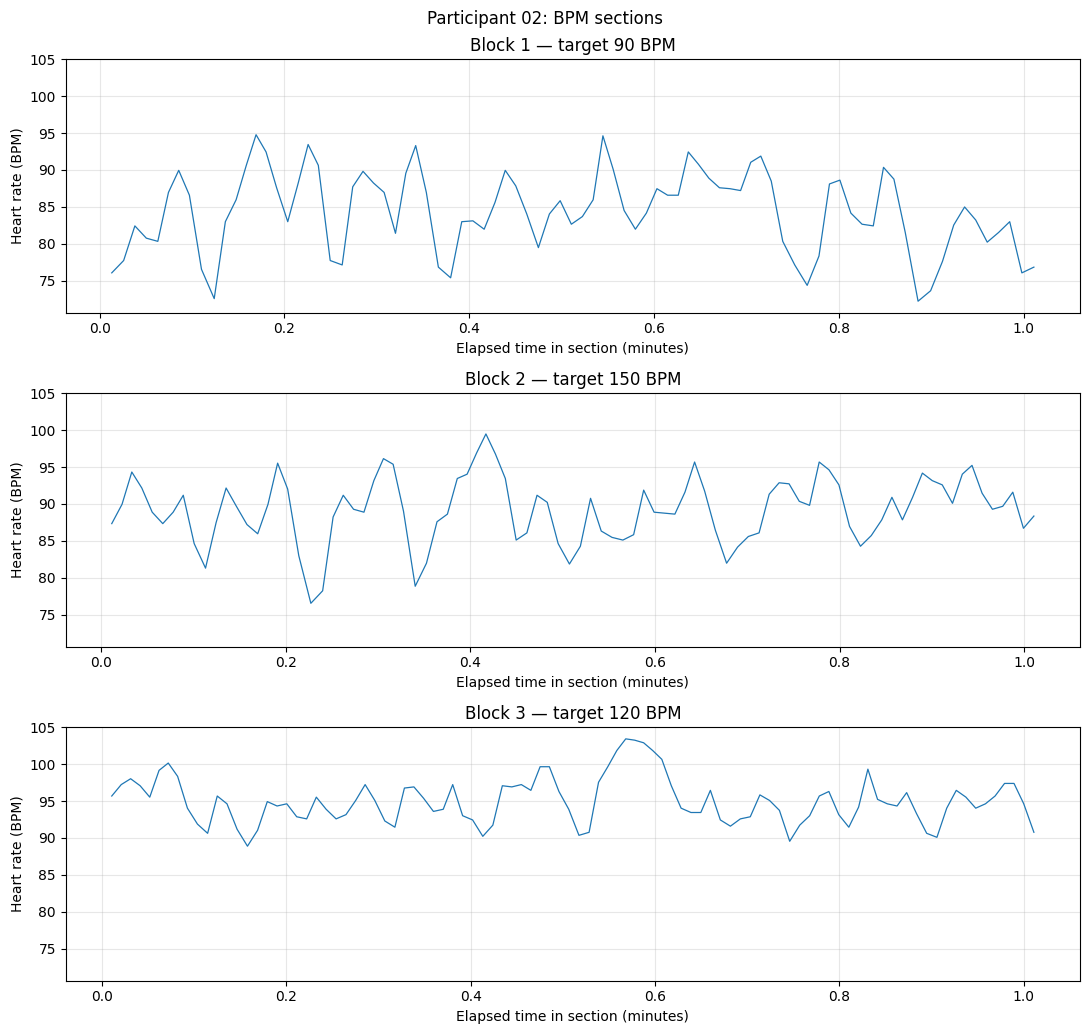

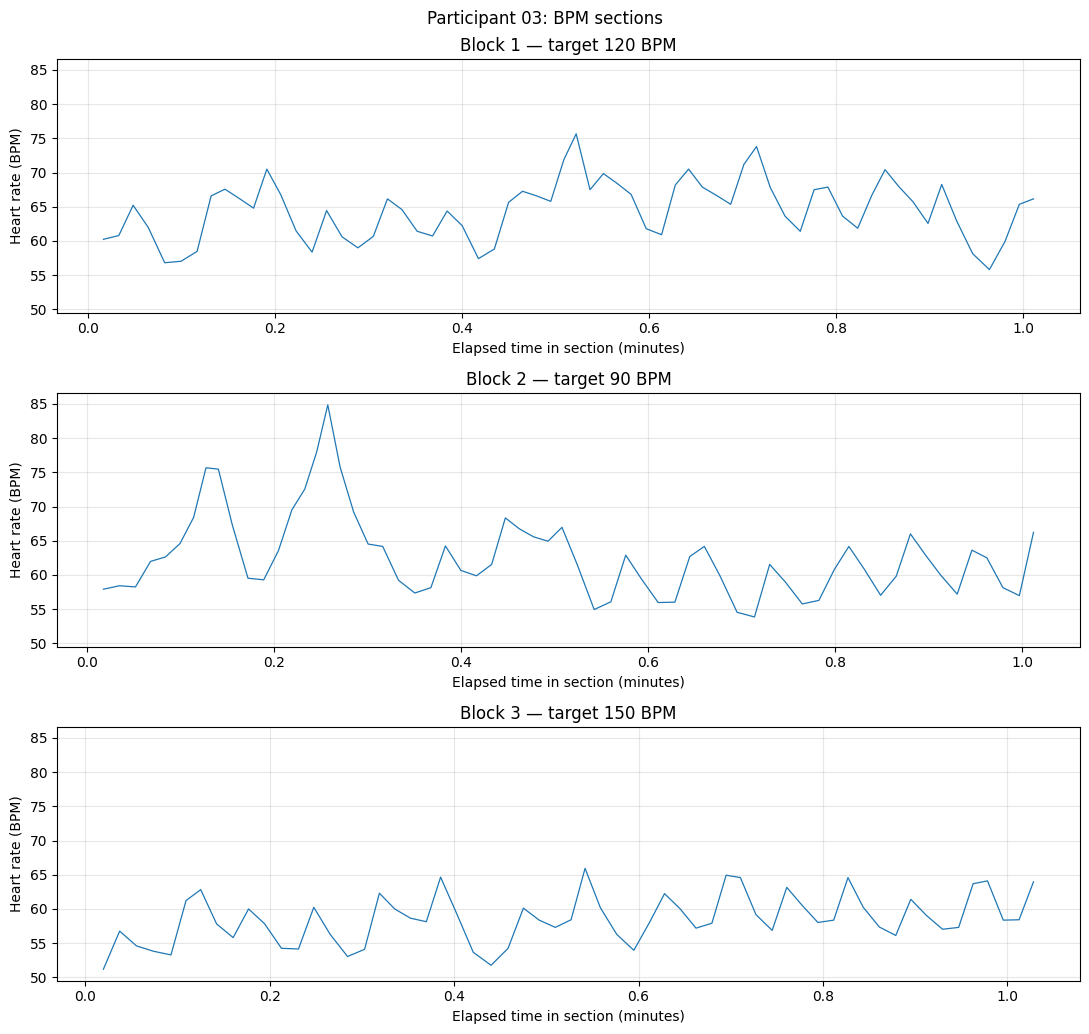

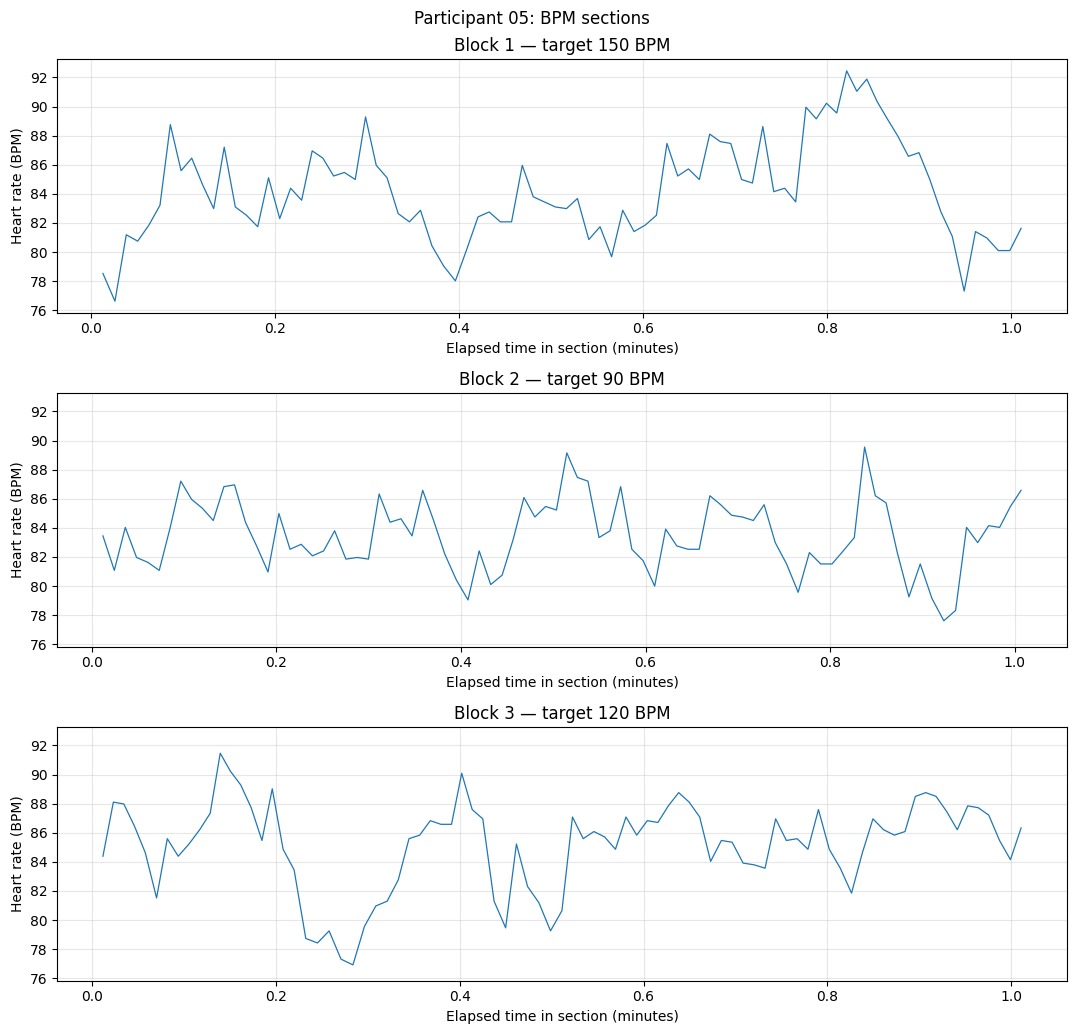

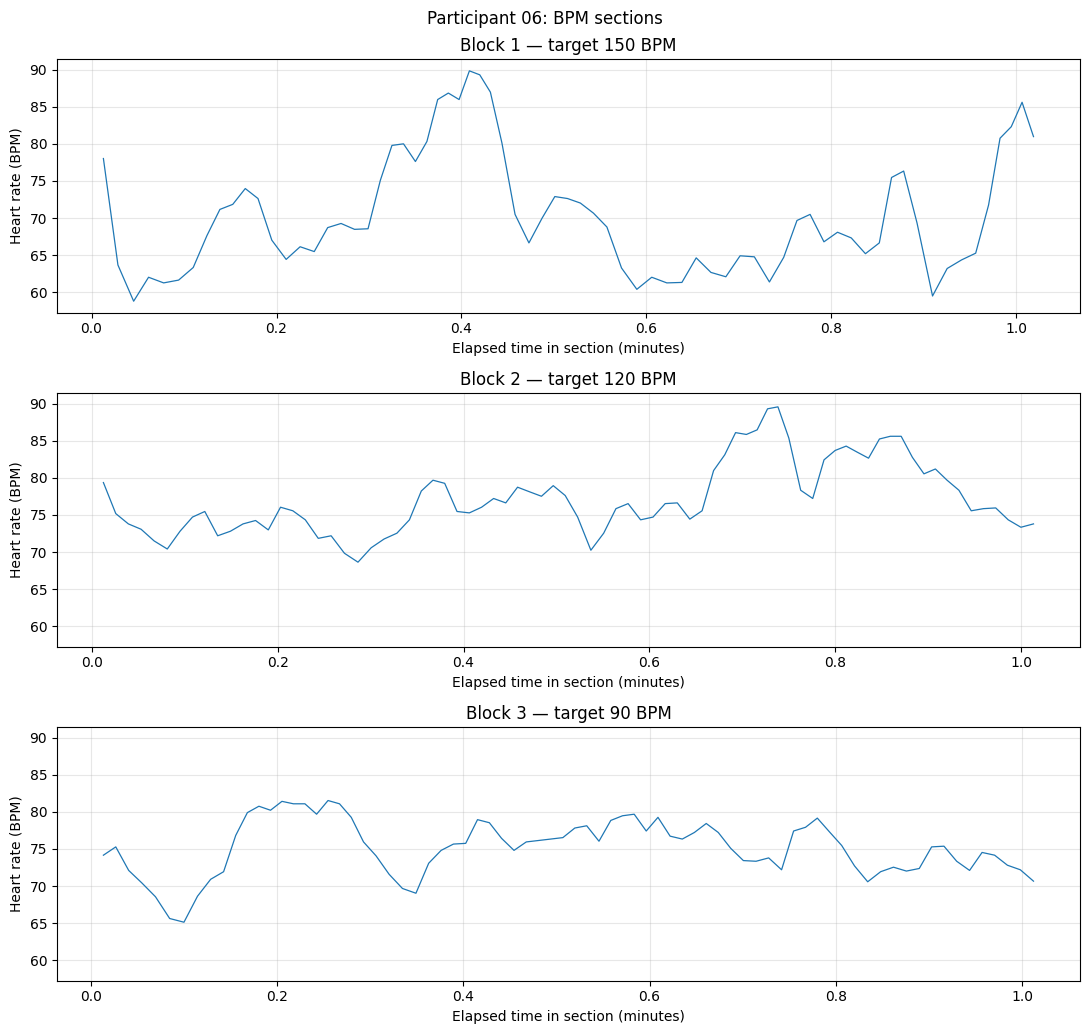

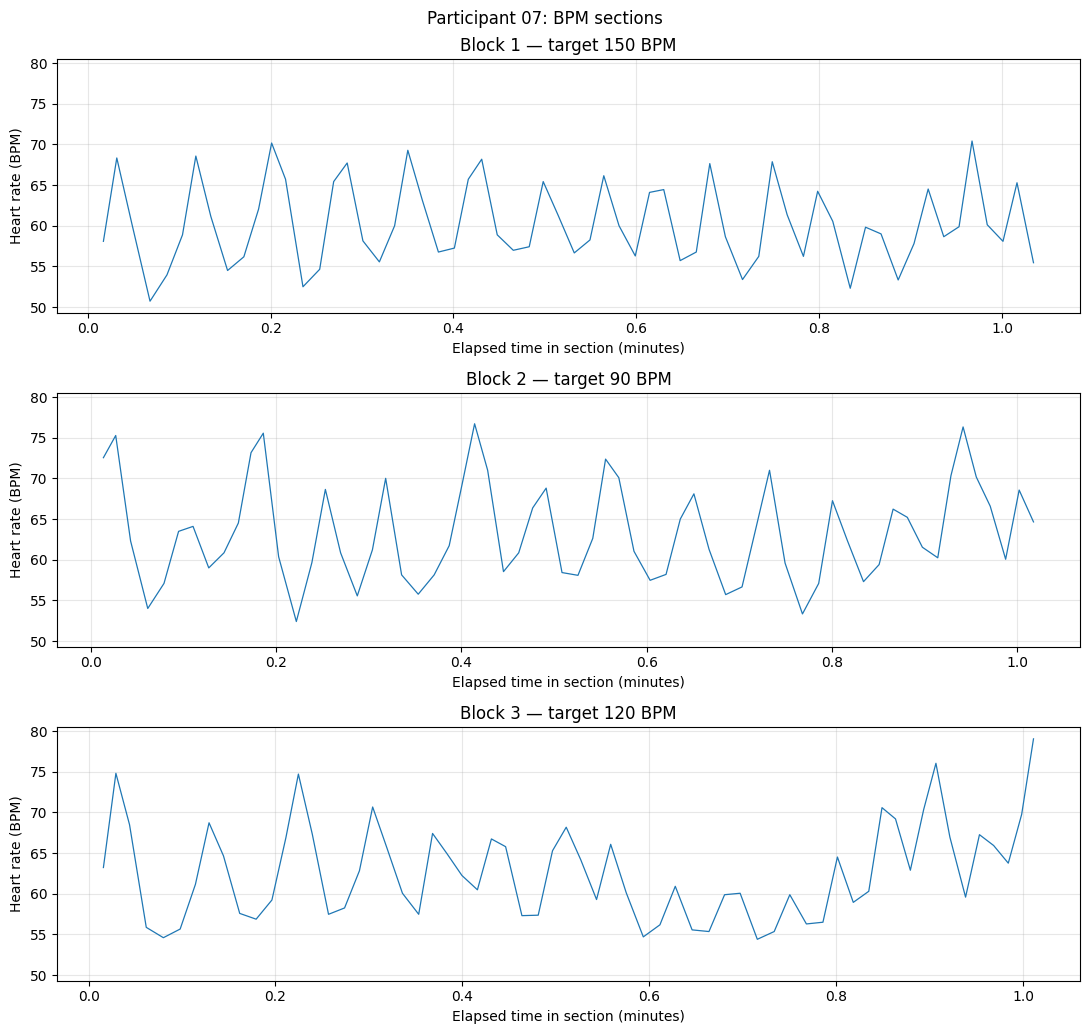

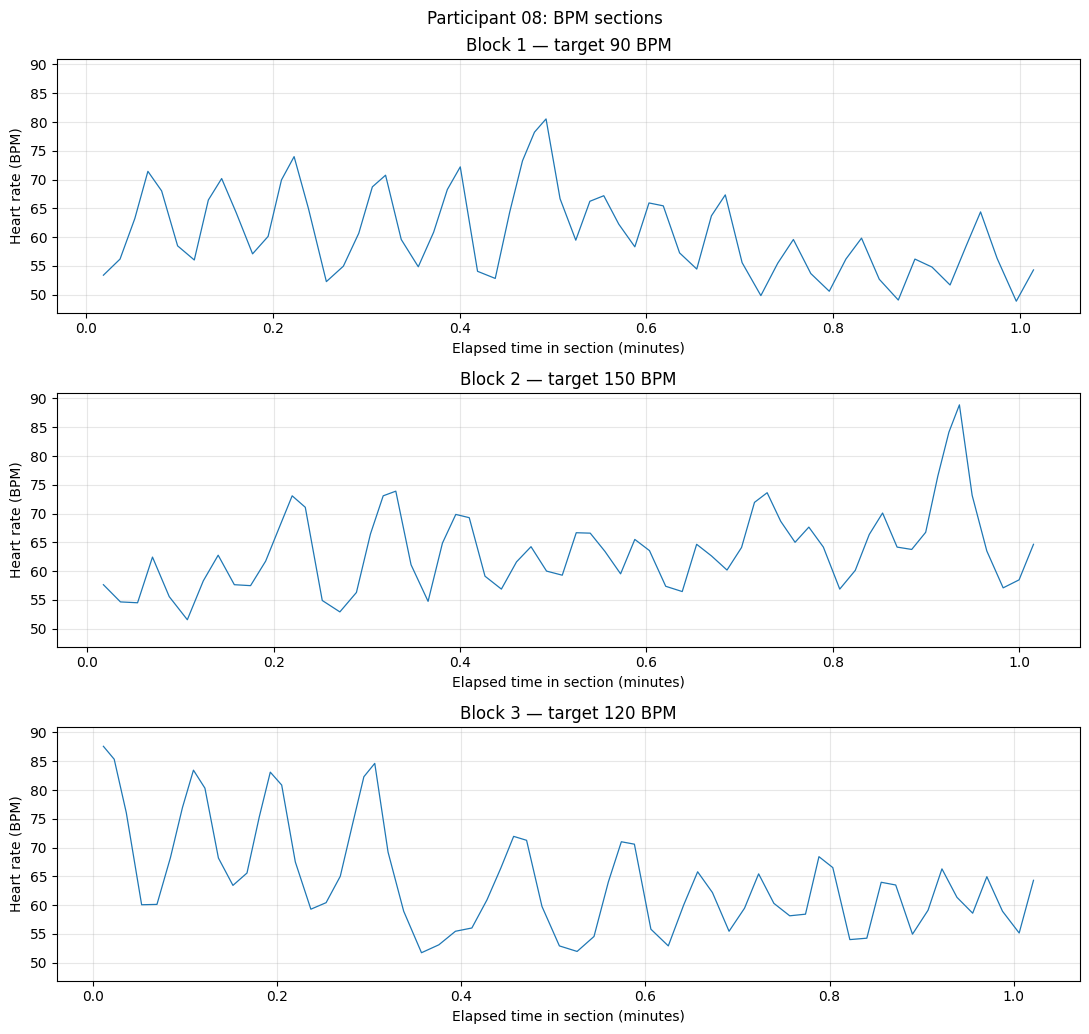

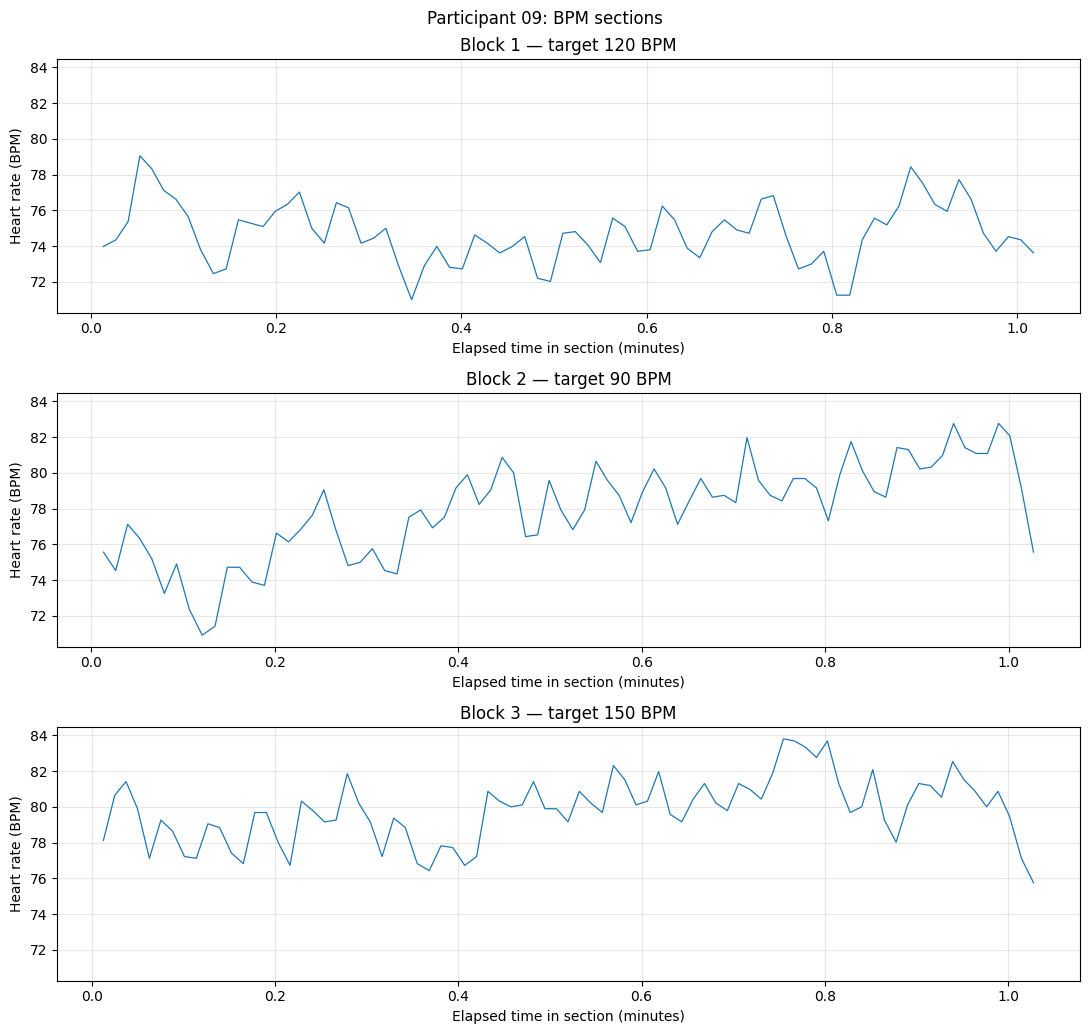

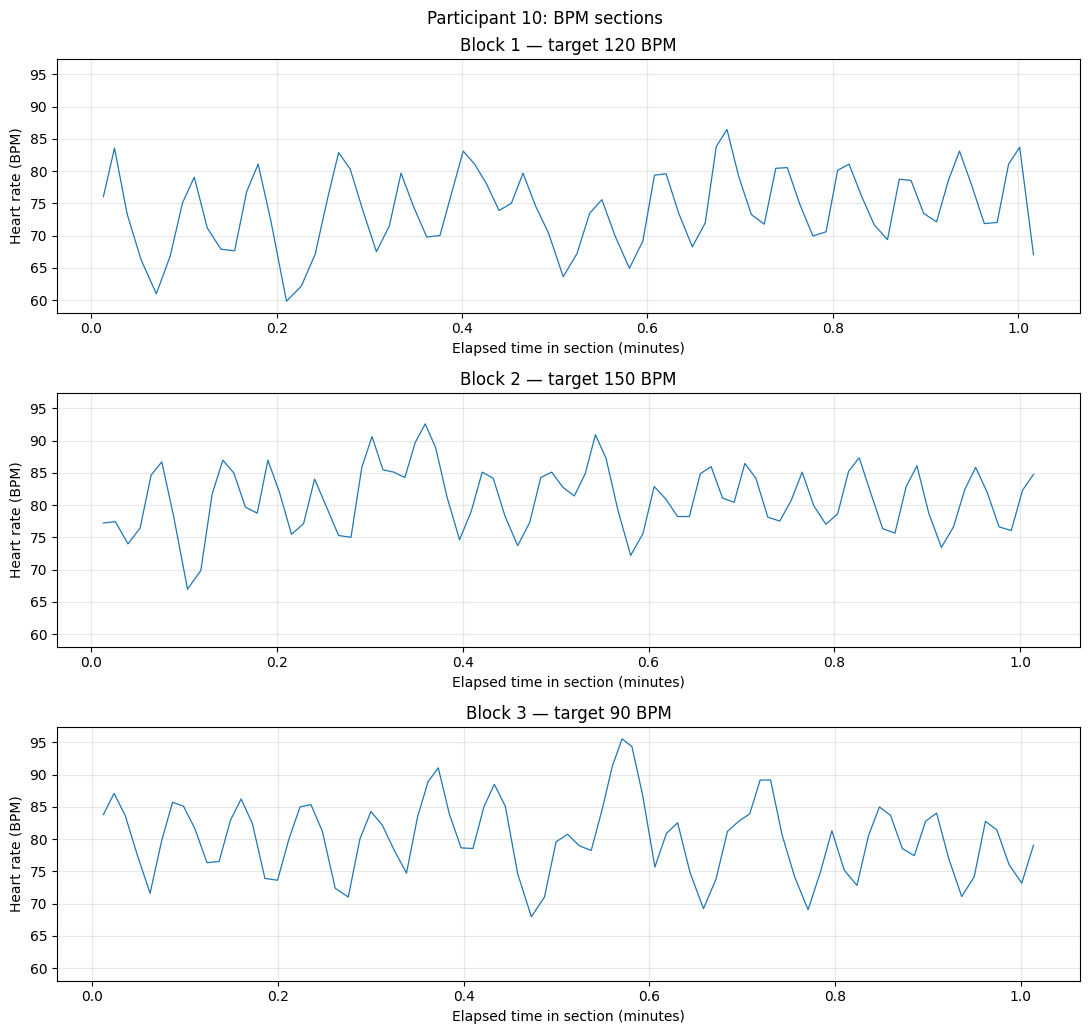

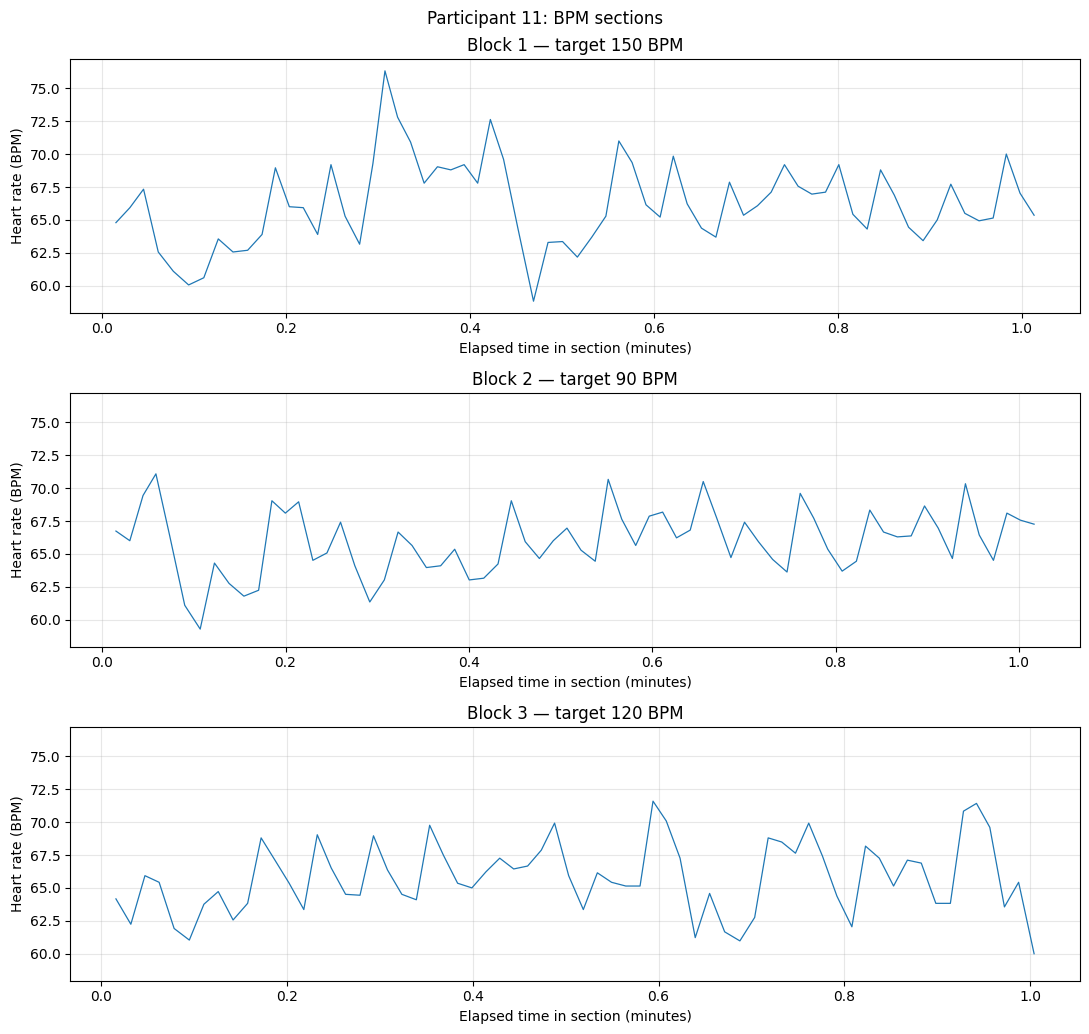

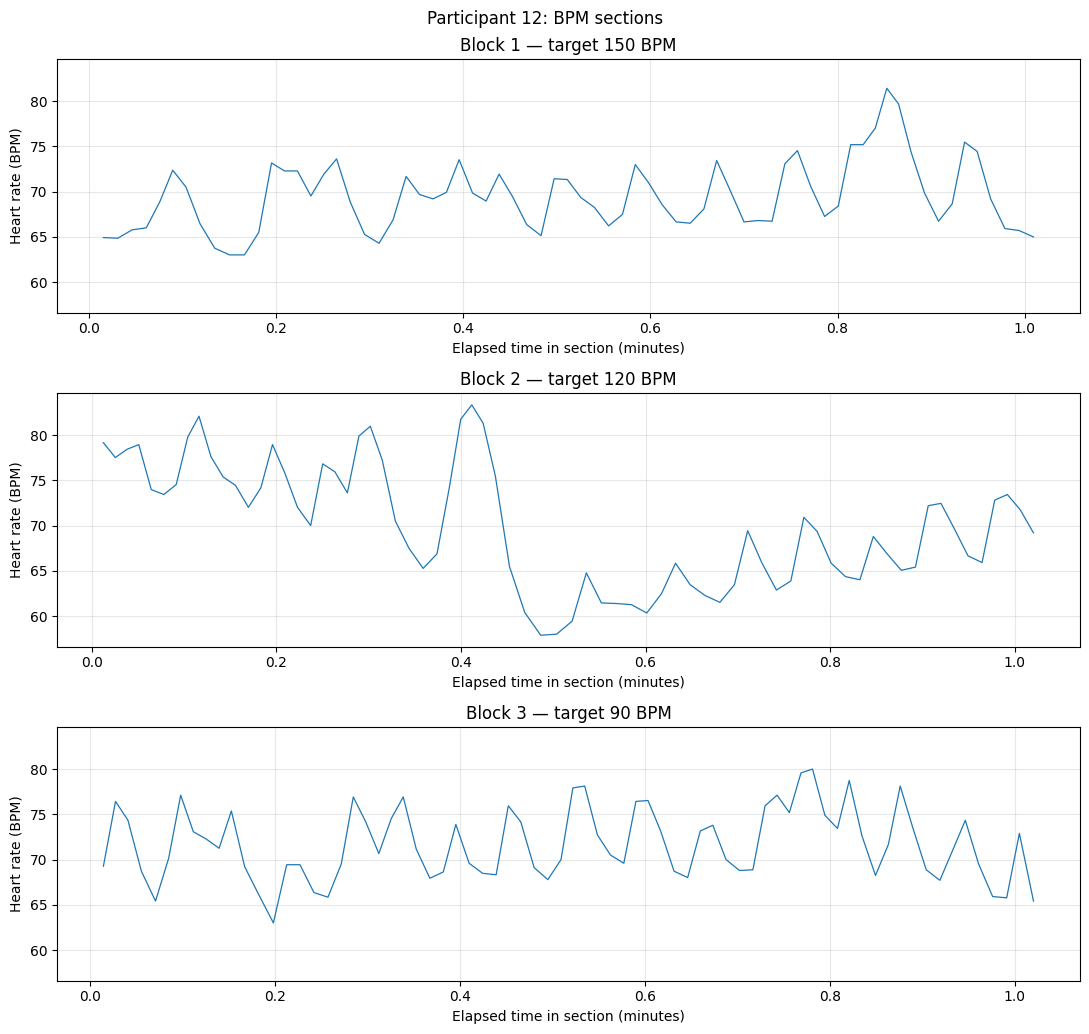

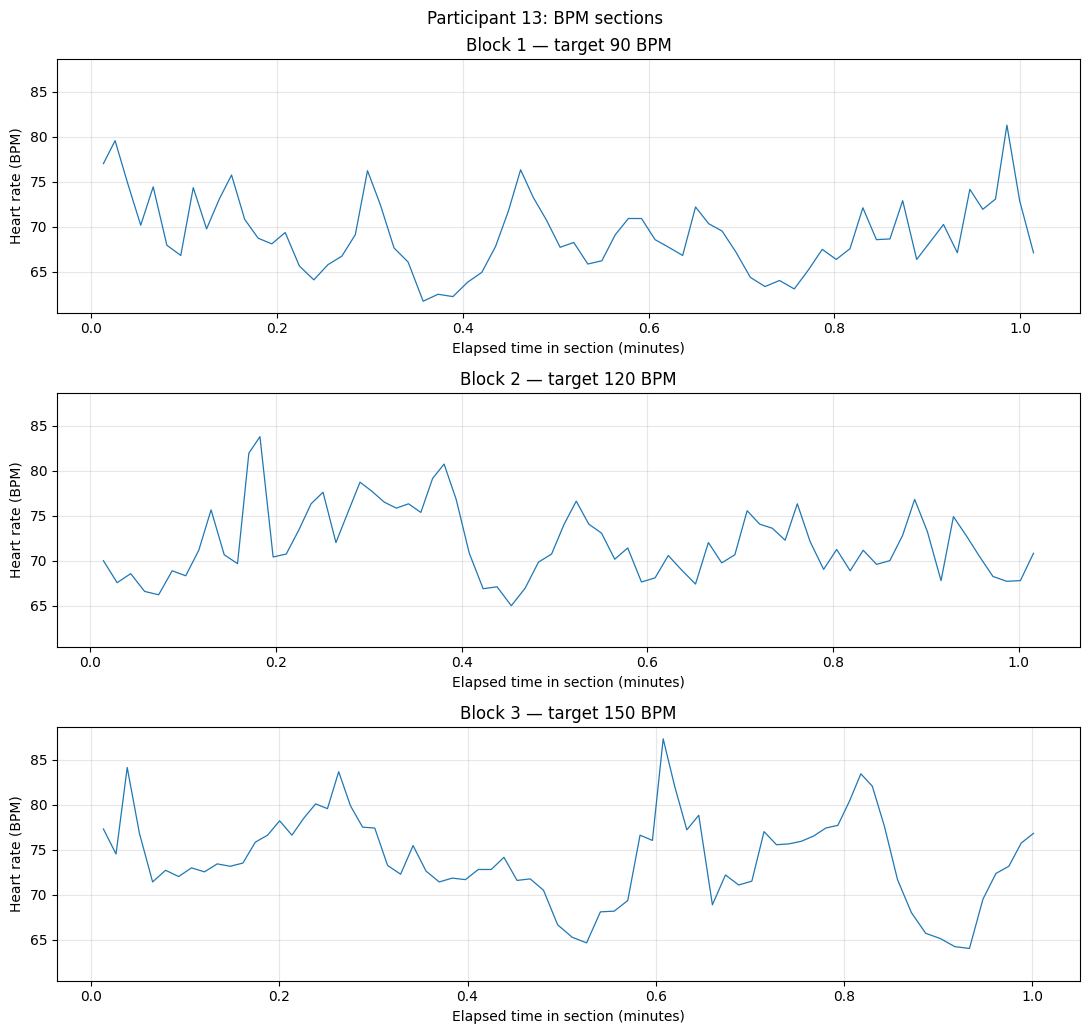

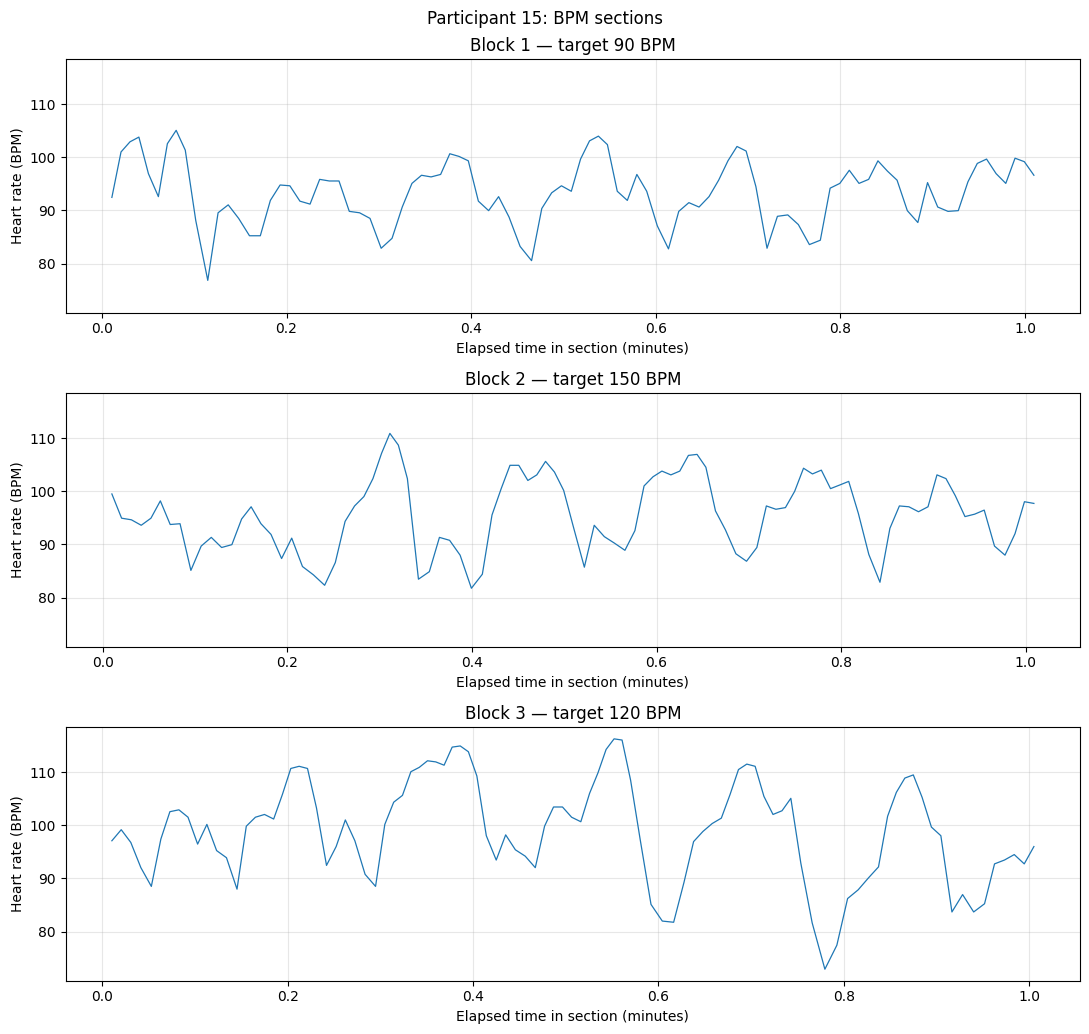

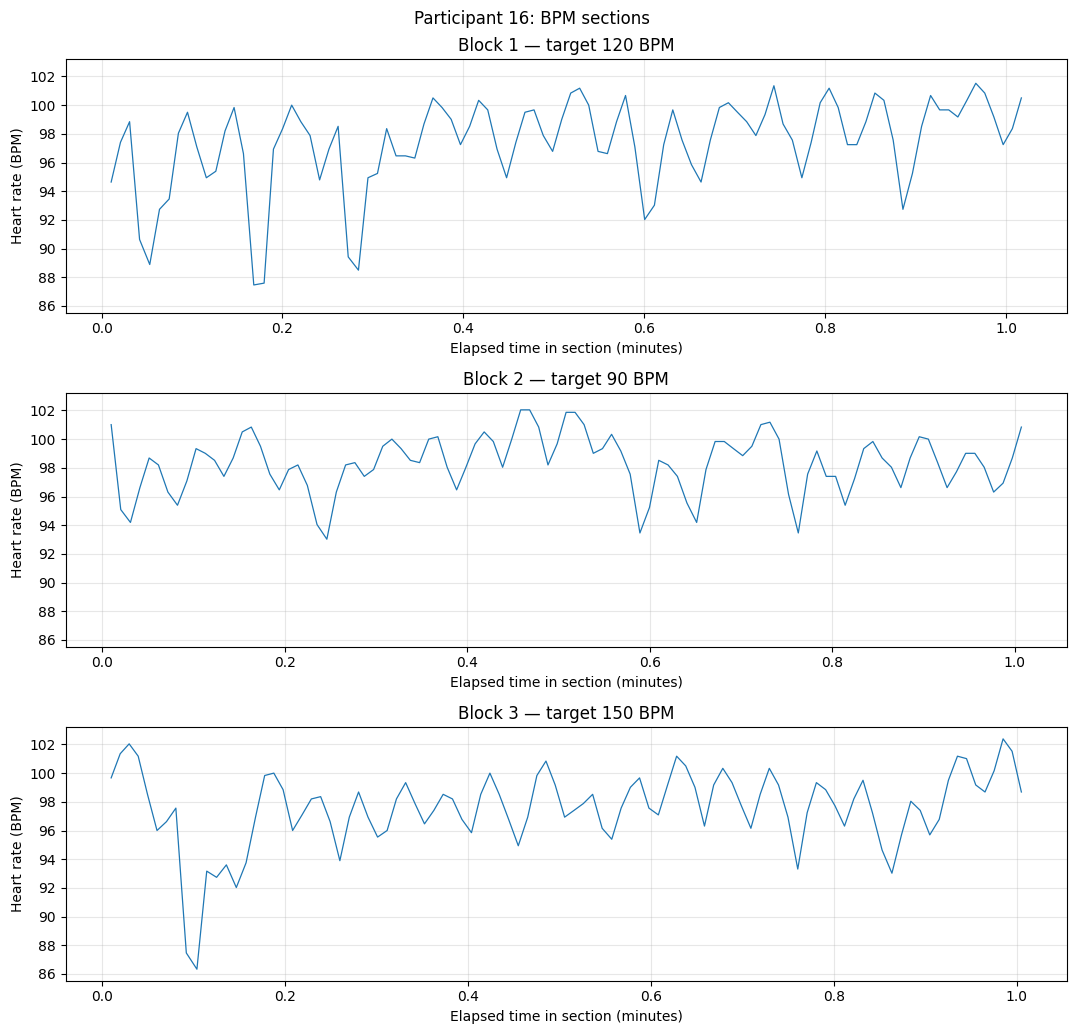

In [ ]:
import csv
import re
from pathlib import Path

import matplotlib.pyplot as plt

SECTIONS_DIR = Path("data-cut") / "bpm_sections"
PLOT_DIR = Path("data-cut") / "bpm_section_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

sections_by_participant = {}

for csv_path in sorted(SECTIONS_DIR.glob("*.csv")):
    match = re.search(
        r"participant-(\d+)_block-(\d+)_([0-9.]+)bpm",
        csv_path.stem,
    )
    if not match:
        continue

    participant_id, block_number, target_bpm = match.groups()

    with csv_path.open(encoding="utf-8-sig", newline="") as f:
        rows = list(csv.reader(f, delimiter=";"))[3:]

    elapsed_seconds = 0.0
    elapsed_minutes = []
    heart_rate_bpm = []

    for row in rows:
        if len(row) < 2 or not row[1].strip():
            continue

        rr_ms = float(row[1])
        if rr_ms <= 0:
            continue

        elapsed_seconds += rr_ms / 1000
        elapsed_minutes.append(elapsed_seconds / 60)
        heart_rate_bpm.append(60_000 / rr_ms)

    if elapsed_minutes:
        sections_by_participant.setdefault(participant_id, []).append(
            (int(block_number), target_bpm, elapsed_minutes, heart_rate_bpm)
        )

for participant_id, sections in sorted(sections_by_participant.items()):
    sections.sort(key=lambda section: section[0])

    fig, axes = plt.subplots(
        len(sections),
        1,
        figsize=(11, 3.5 * len(sections)),
        sharey=True,
        squeeze=False,
    )

    for ax, (block_number, target_bpm, elapsed, heart_rate) in zip(
        axes.flat, sections
    ):
        ax.plot(elapsed, heart_rate, linewidth=0.9)
        ax.set_title(f"Block {block_number} — target {target_bpm} BPM")
        ax.set_xlabel("Elapsed time in section (minutes)")
        ax.set_ylabel("Heart rate (BPM)")
        ax.grid(True, alpha=0.3)

    fig.suptitle(f"Participant {participant_id}: BPM sections")
    fig.tight_layout()
    #fig.savefig(
        #PLOT_DIR / f"participant-{participant_id}_bpm_sections.png",
        #dpi=200,
    #)
    plt.show()

We computed pariwise Pearson correlations for each BPM condition.

In [14]:
from pathlib import Path
from datetime import datetime, timedelta
from bisect import bisect_left
import csv
import re

PROJECT_DIR = Path(
    "/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science"
)
DATA_DIR = PROJECT_DIR / "data"

PARTICIPANT_DIR = PROJECT_DIR / "data copy"
if not PARTICIPANT_DIR.exists():
    PARTICIPANT_DIR = DATA_DIR

SECTIONS_DIR = PROJECT_DIR / "data-cut" / "bpm_sections"
MAX_INTERPOLATION_GAP_SECONDS = 3.0
INTERPOLATION_STEP_SECONDS = 1.0

blocks_by_key = {}

for participant_folder in PARTICIPANT_DIR.glob("participant-*"):
    participant_id = participant_folder.name.split("-")[-1]
    blocks_path = participant_folder / "blocks.csv"

    if not blocks_path.exists():
        continue

    with blocks_path.open(encoding="utf-8-sig", newline="") as f:
        for block in csv.DictReader(f):
            if block.get("segment") != "block":
                continue

            blocks_by_key[
                (participant_id, int(block["block_index"]))
            ] = {
                "target_bpm": int(float(block["condition_bpm"])),
                "start": datetime.fromisoformat(
                    f"{block['date']}T{block['start_local']}"
                ),
                "stop": datetime.fromisoformat(
                    f"{block['date']}T{block['stop_local']}"
                ),
            }


def interpolate_at(x_values, y_values, target_x):
    index = bisect_left(x_values, target_x)

    if index < len(x_values) and x_values[index] == target_x:
        return y_values[index]

    if index == 0 or index == len(x_values):
        return None

    left_x = x_values[index - 1]
    right_x = x_values[index]

    if right_x - left_x > MAX_INTERPOLATION_GAP_SECONDS:
        return None

    fraction = (target_x - left_x) / (right_x - left_x)
    return y_values[index - 1] + fraction * (
        y_values[index] - y_values[index - 1]
    )


profiles = {90: {}, 120: {}, 150: {}}
lmm_rows = []

for section_path in sorted(SECTIONS_DIR.glob("*.csv")):
    match = re.search(
        r"participant-(\d+)_block-(\d+)_([0-9.]+)bpm",
        section_path.stem,
    )
    if not match:
        continue

    participant_id, block_index, filename_bpm = match.groups()
    participant_id = participant_id.zfill(2)
    block_index = int(block_index)

    block = blocks_by_key.get((participant_id, block_index))
    if block is None:
        continue

    with section_path.open(encoding="utf-8-sig", newline="") as f:
        source_rows = list(csv.reader(f, delimiter=";"))

    rows = source_rows[3:]
    block_start = block["start"]
    block_stop = block["stop"]
    block_duration = (block_stop - block_start).total_seconds()

    start_text = source_rows[1][0].replace("Start time:", "").strip()
    section_start = datetime.strptime(
        start_text, "%d.%m.%Y %H:%M:%S"
    )

    # The split-file start time is rounded to seconds. Keep it at or after
    # the actual block start when calculating relative sample times.
    section_offset = max(
        0.0,
        (section_start - block_start).total_seconds(),
    )

    elapsed_seconds = 0.0
    section_times = []
    section_hrs = []

    for row in rows:
        if len(row) < 2 or not row[1].strip():
            continue

        rr_ms = float(row[1])
        if rr_ms <= 0:
            continue

        rr_seconds = rr_ms / 1000
        beat_start_s = section_offset + elapsed_seconds
        beat_stop_s = beat_start_s + rr_seconds
        beat_midpoint_s = (beat_start_s + beat_stop_s) / 2
        hr_bpm = 60_000 / rr_ms

        elapsed_seconds += rr_seconds

        # Keep intervals wholly inside the block.
        if beat_start_s < 0 or beat_stop_s > block_duration:
            continue

        section_times.append(beat_midpoint_s)
        section_hrs.append(hr_bpm)

        raw_artifact = (
            int(float(row[2]))
            if len(row) > 2 and row[2].strip()
            else None
        )

        lmm_rows.append({
            "participant_id": participant_id,
            "target_bpm": block["target_bpm"],
            "block_index": block_index,
            "time_s": beat_midpoint_s,
            "hr_bpm": hr_bpm,
            "corrected_rr_ms": rr_ms,
            "raw_artifact": raw_artifact,
            "recording_file": section_path.name,
        })

    if len(section_times) < 3:
        continue

    profile = {}
    grid_time = INTERPOLATION_STEP_SECONDS

    while grid_time < block_duration:
        value = interpolate_at(section_times, section_hrs, grid_time)
        if value is not None:
            profile[grid_time] = value
        grid_time += INTERPOLATION_STEP_SECONDS

    if profile:
        bpm = block["target_bpm"]
        profiles[bpm][participant_id] = profile

print(
    "Profiles loaded:",
    {bpm: len(profiles[bpm]) for bpm in (90, 120, 150)},
)
print("Beat-level rows loaded for the LMM:", len(lmm_rows))

Profiles loaded: {90: 13, 120: 13, 150: 13}
Beat-level rows loaded for the LMM: 2959


In [15]:
import pandas as pd

def pearson_r(x_values, y_values):
    if len(x_values) < 3:
        return None

    mean_x = sum(x_values) / len(x_values)
    mean_y = sum(y_values) / len(y_values)

    numerator = sum(
        (x - mean_x) * (y - mean_y)
        for x, y in zip(x_values, y_values)
    )
    denominator = (
        sum((x - mean_x) ** 2 for x in x_values)
        * sum((y - mean_y) ** 2 for y in y_values)
    ) ** 0.5

    return numerator / denominator if denominator else None


pairwise_rows = []

for bpm in (90, 120, 150):
    condition_profiles = profiles[bpm]
    participant_ids = sorted(condition_profiles)

    for i, participant_a in enumerate(participant_ids):
        for participant_b in participant_ids[i + 1:]:
            profile_a = condition_profiles[participant_a]
            profile_b = condition_profiles[participant_b]
            shared_times = sorted(set(profile_a) & set(profile_b))

            r = pearson_r(
                [profile_a[t] for t in shared_times],
                [profile_b[t] for t in shared_times],
            )

            if r is not None:
                pairwise_rows.append({
                    "target_bpm": bpm,
                    "participant_a": participant_a,
                    "participant_b": participant_b,
                    "pearson_r": r,
                    "shared_grid_points": len(shared_times),
                })

pairwise_df = pd.DataFrame(pairwise_rows)

display(
    pairwise_df.groupby("target_bpm")["pearson_r"]
    .agg(
        participants_pairs="count",
        mean_r="mean",
        median_r="median",
        min_r="min",
        max_r="max",
    )
    .round(3)
)

,participants_pairs,mean_r,median_r,min_r,max_r
target_bpm,,,,,
90,78,-0.013,-0.012,-0.367,0.448
120,78,-0.016,-0.042,-0.472,0.525
150,78,0.057,0.062,-0.433,0.443


We give each participant their average Fisher-transformed correlation with the other participants. Then fit an LMM with tempo and block order as fixed effects and participant as a random intercept.

In [16]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display

# Map each participant and tempo to its block order.
block_order = {}
for row in lmm_rows:
    key = (str(row["participant_id"]), int(row["target_bpm"]))
    block_order[key] = int(row["block_index"])

# Give each participant their Fisher-z correlation with each partner.
participant_pair_scores = []

for row in pairwise_rows:
    r = np.clip(row["pearson_r"], -0.999999, 0.999999)
    z = np.arctanh(r)
    bpm = int(row["target_bpm"])

    for participant_id in (
        str(row["participant_a"]),
        str(row["participant_b"]),
    ):
        participant_pair_scores.append({
            "participant_id": participant_id,
            "target_bpm": bpm,
            "block_index": block_order[(participant_id, bpm)],
            "fisher_z": z,
        })

# Average each participant's correlations with their partners per tempo.
participant_sync = (
    pd.DataFrame(participant_pair_scores)
    .groupby(
        ["participant_id", "target_bpm", "block_index"],
        as_index=False,
    )
    .agg(
        mean_z_sync=("fisher_z", "mean"),
        n_partners=("fisher_z", "size"),
    )
)

participant_sync["target_bpm"] = pd.Categorical(
    participant_sync["target_bpm"],
    categories=[90, 120, 150],
)
participant_sync["block_index"] = pd.Categorical(
    participant_sync["block_index"],
    categories=[1, 2, 3],
)

# Test whether participant-level synchrony scores differ by tempo,
# controlling for block order, with a random intercept for participant.
model = smf.mixedlm(
    "mean_z_sync ~ C(target_bpm) + C(block_index)",
    data=participant_sync,
    groups=participant_sync["participant_id"],
    re_formula="1",
)
result = model.fit(reml=True, method="lbfgs")

print(result.summary())

display(
    participant_sync.groupby("target_bpm", observed=True)
    .agg(
        mean_z_sync=("mean_z_sync", "mean"),
        participants=("participant_id", "nunique"),
    )
    .reset_index()
)

             Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   mean_z_sync
No. Observations:   39        Method:               REML       
No. Groups:         13        Scale:                0.0025     
Min. group size:    3         Log-Likelihood:       47.6254    
Max. group size:    3         Converged:            Yes        
Mean group size:    3.0                                        
---------------------------------------------------------------
                     Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------
Intercept             0.000    0.025  0.000 1.000 -0.049  0.049
C(target_bpm)[T.120] -0.002    0.020 -0.082 0.934 -0.041  0.038
C(target_bpm)[T.150]  0.072    0.020  3.636 0.000  0.033  0.111
C(block_index)[T.2]   0.004    0.020  0.221 0.825 -0.035  0.043
C(block_index)[T.3]  -0.004    0.020 -0.200 0.841 -0.043  0.035
Group Var             0.000    0.020                 

/Users/denisa-student/.local/lib/python3.11/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/var/folders/52/cnr2_8nx2mncwgy2ygk46jpw0000gp/T/ipykernel_18193/1405525558.py:61: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  result = model.fit(reml=True, method="lbfgs")


,target_bpm,mean_z_sync,participants
0,90,-0.012574,13
1,120,-0.016169,13
2,150,0.058737,13


Under this model, 150 BPM has a higher synchrony score than 90 BPM, while 120 BPM does not differ detectably from 90 BPM.

We continued with the analysis of the groove ratings.

In [17]:
from pathlib import Path
import csv
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path(
    "/Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science"
)

PARTICIPANT_DIR = PROJECT_DIR / "data copy"
if not PARTICIPANT_DIR.exists():
    PARTICIPANT_DIR = PROJECT_DIR / "data"

OUTPUT_PATH = PROJECT_DIR / "data-cut" / "grooviness_ratings_by_bpm.csv"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

ratings = {
    1:  [4, 4, 3],
    2:  [2, 3, 4],
    3:  [2, 1, 2],
    4:  [4, 2, 3],
    5:  [4, 3, 5],
    6:  [3, 2, 4],
    7:  ["", "", ""],
    8:  [4, 2, 3],
    9:  [3, 4, 2],
    10: [2, 4, 3],
    11: [3, 4, 5],
    12: ["", "", ""],
    13: [1, 4, 5],
    14: [3, 2, 4],
    15: [1, 2, 1],
    16: [1, 3, 4],
    17: [2, 1, 4],
    18: [4, 2, 3],
}

csv_rows = []
participants_without_block_mapping = []

for participant_id, participant_ratings in ratings.items():
    blocks_path = (
        PARTICIPANT_DIR
        / f"participant-{participant_id:02d}"
        / "blocks.csv"
    )
    bpm_by_block = {}

    if blocks_path.exists():
        with blocks_path.open(encoding="utf-8-sig", newline="") as f:
            for block in csv.DictReader(f):
                if block.get("segment") == "block":
                    bpm_by_block[int(block["block_index"])] = int(
                        float(block["condition_bpm"])
                    )
    else:
        participants_without_block_mapping.append(participant_id)

    for block_index, grooviness in enumerate(participant_ratings, start=1):
        csv_rows.append({
            "participant_id": f"{participant_id:02d}",
            "listening_block": block_index,
            "bpm": bpm_by_block.get(block_index, ""),
            "grooviness": grooviness,
        })

grooviness_df = pd.DataFrame(csv_rows)
grooviness_df.to_csv(OUTPUT_PATH, index=False, na_rep="")

display(grooviness_df)
print(f"Saved CSV to: {OUTPUT_PATH}")

if participants_without_block_mapping:
    print(
        "No blocks.csv mapping found for participants:",
        ", ".join(f"{pid:02d}" for pid in participants_without_block_mapping),
    )

,participant_id,listening_block,bpm,grooviness
0,01,1,90,4
1,01,2,120,4
2,01,3,150,3
3,02,1,90,2
4,02,2,150,3
5,02,3,120,4
6,03,1,120,2
7,03,2,90,1
8,03,3,150,2
9,04,1,120,4


Saved CSV to: /Volumes/CECORE512GB/Master/Experiment/Experiment-in-Cognitive-Science/data-cut/grooviness_ratings_by_bpm.csv
No blocks.csv mapping found for participants: 17, 18


We checked the average grooviness per BPM.

In [18]:
summary_df = grooviness_df.copy()
summary_df["bpm"] = pd.to_numeric(summary_df["bpm"], errors="coerce")
summary_df["grooviness"] = pd.to_numeric(
    summary_df["grooviness"], errors="coerce"
)

average_rating_by_bpm = (
    summary_df.dropna(subset=["bpm", "grooviness"])
    .groupby("bpm")
    .agg(
        average_grooviness=("grooviness", "mean"),
        n_ratings=("grooviness", "count"),
    )
    .reset_index()
)

display(average_rating_by_bpm.round(2))

,bpm,average_grooviness,n_ratings
0,90.0,2.86,14
1,120.0,3.00,14
2,150.0,3.07,14
